<a href="https://colab.research.google.com/github/TheAraibKhan/Natural-Language-Processing-Lab/blob/main/NLP_Practical_22_RNN_LSTM.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Vocabulary Size: 35
Maximum Sequence Length: 7

Padded Sequences:
[[ 4  3  5  9  2 17  0]
 [ 7 18 19  4 20  3  0]
 [ 6  8 10 21  2 22  0]
 [ 4  5 11 23  2 24  3]
 [ 6 12  5 25  2  9  0]
 [ 7 26  6  3 13 27  0]
 [ 4  3  5 14  2 15  0]
 [ 7 28  4 29  2 16  8]
 [ 6  8 10 30  2 13 31]
 [ 4  5 11 32  2 15  3]
 [ 6 12  5 16  2 14  0]
 [ 7 33  6  3 34  0  0]]


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

Epoch 1/30
3/3 ━━━━━━━━━━━━━━━━━━━━ 2s 15ms/step - accuracy: 0.2500 - loss: 0.6946
Epoch 2/30
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.5000 - loss: 0.6930
Epoch 3/30
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.5000 - loss: 0.6918
Epoch 4/30
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.5000 - loss: 0.6925
Epoch 5/30
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.5000 - loss: 0.6907
Epoch 6/30
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.6667 - loss: 0.6906
Epoch 7/30
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.5833 - loss: 0.6896
Epoch 8/30
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.6667 - loss: 0.6888
Epoch 9/30
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.7500 - loss: 0.6878
Epoch 10/30
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.8333 - loss: 0.6882
Epoch 11/30
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.8333 - loss: 0.6843
Epoch 12/30
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.7500 - loss: 0.6857
E

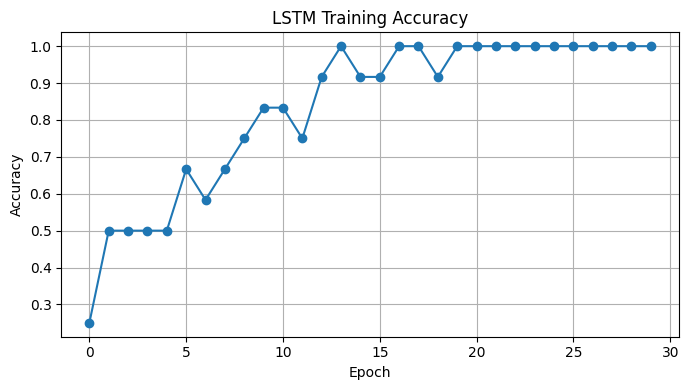


NEW TEXT CLASSIFICATION:

Text: this movie was amazing and enjoyable
Prediction Score: 0.8310
Sentiment: Positive

Text: this film was awful and boring
Prediction Score: 0.3417
Sentiment: Negative

Text: the acting was excellent
Prediction Score: 0.7748
Sentiment: Positive

Text: i hate this terrible movie
Prediction Score: 0.3371
Sentiment: Negative

RESULT:
Text sequences were classified using an LSTM neural network.

CONCLUSION:
LSTM learns sequential patterns from text data and uses
them to classify input sequences into sentiment categories.


In [1]:
# ============================================================
# PRACTICAL 22: SEQUENCE CLASSIFICATION USING RNN / LSTM
# Course Outcome: CO2
# ============================================================

# OBJECTIVE:
# To perform text sequence classification using an LSTM neural network.

# Install required library
!pip -q install tensorflow

# Import libraries
import numpy as np
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout
from tensorflow.keras.utils import set_random_seed

set_random_seed(42)

# ------------------------------------------------------------
# 1. PREPARE TEXT DATASET
# ------------------------------------------------------------

texts = [
    "this movie is excellent and wonderful",
    "i really love this amazing movie",
    "the film was fantastic and enjoyable",
    "this is a great and beautiful movie",
    "the acting is brilliant and excellent",
    "i enjoyed the movie very much",
    "this movie is terrible and boring",
    "i hate this awful and disappointing film",
    "the film was horrible and very bad",
    "this is a poor and boring movie",
    "the acting is disappointing and terrible",
    "i disliked the movie completely"
]

labels = np.array([1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0])

# 1 = Positive, 0 = Negative

# ------------------------------------------------------------
# 2. TOKENIZATION AND SEQUENCE PREPARATION
# ------------------------------------------------------------

tokenizer = Tokenizer(num_words=1000, oov_token="<OOV>")
tokenizer.fit_on_texts(texts)

sequences = tokenizer.texts_to_sequences(texts)

max_length = max(len(sequence) for sequence in sequences)

padded_sequences = pad_sequences(
    sequences,
    maxlen=max_length,
    padding="post",
    truncating="post"
)

vocab_size = min(1000, len(tokenizer.word_index) + 1)

print("Vocabulary Size:", vocab_size)
print("Maximum Sequence Length:", max_length)
print("\nPadded Sequences:")
print(padded_sequences)

# ------------------------------------------------------------
# 3. BUILD LSTM MODEL
# ------------------------------------------------------------

model = Sequential([
    Embedding(vocab_size, 16, input_length=max_length),
    LSTM(32),
    Dropout(0.2),
    Dense(16, activation="relu"),
    Dense(1, activation="sigmoid")
])

model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model.summary()

# ------------------------------------------------------------
# 4. TRAIN THE MODEL
# ------------------------------------------------------------

history = model.fit(
    padded_sequences,
    labels,
    epochs=30,
    batch_size=4,
    verbose=1
)

# ------------------------------------------------------------
# 5. VISUALIZE TRAINING ACCURACY
# ------------------------------------------------------------

import matplotlib.pyplot as plt

plt.figure(figsize=(7, 4))
plt.plot(history.history["accuracy"], marker="o")
plt.title("LSTM Training Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.grid(True)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 6. CLASSIFY NEW TEXT SEQUENCES
# ------------------------------------------------------------

new_texts = [
    "this movie was amazing and enjoyable",
    "this film was awful and boring",
    "the acting was excellent",
    "i hate this terrible movie"
]

new_sequences = tokenizer.texts_to_sequences(new_texts)

new_padded = pad_sequences(
    new_sequences,
    maxlen=max_length,
    padding="post",
    truncating="post"
)

predictions = model.predict(new_padded, verbose=0)

print("\nNEW TEXT CLASSIFICATION:")

for text, prediction in zip(new_texts, predictions):
    sentiment = "Positive" if prediction[0] >= 0.5 else "Negative"
    print(f"\nText: {text}")
    print(f"Prediction Score: {prediction[0]:.4f}")
    print(f"Sentiment: {sentiment}")

# ------------------------------------------------------------
# 7. RESULT AND CONCLUSION
# ------------------------------------------------------------

print("\nRESULT:")
print("Text sequences were classified using an LSTM neural network.")

print("\nCONCLUSION:")
print("LSTM learns sequential patterns from text data and uses")
print("them to classify input sequences into sentiment categories.")